# Large Dataset - Benign-Only Autoencoder

This notebook evaluates large-scale benign-only Autoencoder training on CSE-CIC-IDS2018.

The model is trained exclusively on benign network traffic and evaluated on controlled test sets containing DoS-GoldenEye anomalies at multiple prevalence levels.

## Import Libraries

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

import optuna

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Optuna:", optuna.__version__)

Python: 3.12.7
TensorFlow: 2.21.0
Optuna: 5.0.0


c:\Projects\Computer-Log-Anomaly-Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load CSE-CIC-IDS2018 Dataset

In [2]:
DATA_PATH = Path("../data/medium/02-15-2018.csv")

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Raw shape:", df.shape)
print("\nLabel distribution:")
print(df["Label"].value_counts())

Raw shape: (1048575, 80)

Label distribution:
Label
Benign                   996077
DoS attacks-GoldenEye     41508
DoS attacks-Slowloris     10990
Name: count, dtype: int64


## Select Benign and GoldenEye Traffic

Only benign traffic and DoS-GoldenEye attacks are retained. Slowloris is excluded so that the experiment measures detection of one well-defined attack family.

In [3]:
df = df[
    df["Label"].isin([
        "Benign",
        "DoS attacks-GoldenEye"
    ])
].copy()

print("Shape after label filtering:", df.shape)

print("\nLabels:")
print(df["Label"].value_counts())

Shape after label filtering: (1037585, 80)

Labels:
Label
Benign                   996077
DoS attacks-GoldenEye     41508
Name: count, dtype: int64


## Remove Exact Duplicate Records

Exact duplicates are removed before dropping the timestamp so that flows occurring at different times are not incorrectly treated as duplicates.

In [4]:
duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

df = (
    df.drop_duplicates()
    .reset_index(drop=True)
)

print("Shape after duplicate removal:", df.shape)

Exact duplicate rows: 1716
Shape after duplicate removal: (1035869, 80)


## Remove Timestamp

In [5]:
df = df.drop(
    columns=["Timestamp"]
)

print("Shape after removing Timestamp:", df.shape)

Shape after removing Timestamp: (1035869, 79)


## Prepare Numerical Features

Infinite values are converted to missing values. Imputation statistics will be learned later from the benign training set only.

In [6]:
feature_columns = [
    column
    for column in df.columns
    if column != "Label"
]

df[feature_columns] = df[
    feature_columns
].replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Total missing values:",
    df[feature_columns]
    .isna()
    .sum()
    .sum()
)

Total missing values: 16044


## Create Binary Target

In [7]:
df["target"] = df["Label"].map({
    "Benign": 0,
    "DoS attacks-GoldenEye": 1
})

df = df.drop(
    columns=["Label"]
)

print(
    df["target"]
    .value_counts()
    .sort_index()
)

target
0    994414
1     41455
Name: count, dtype: int64


## Separate Benign and Attack Pools

The Autoencoder is trained exclusively on benign traffic. GoldenEye samples remain unseen during model fitting.

In [8]:
benign_data = (
    df[df["target"] == 0]
    .drop(columns="target")
    .reset_index(drop=True)
)

attack_data = (
    df[df["target"] == 1]
    .drop(columns="target")
    .reset_index(drop=True)
)

print("Benign:", benign_data.shape)
print("GoldenEye:", attack_data.shape)

Benign: (994414, 78)
GoldenEye: (41455, 78)


## Large-Scale Benign Training Split

A larger benign training set of 300,000 flows is used to study whether additional normal traffic improves Autoencoder representation learning.

In [9]:
TRAIN_SIZE = 300_000
CALIBRATION_SIZE = 30_000

benign_shuffled = benign_data.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

X_train_benign = benign_shuffled.iloc[
    :TRAIN_SIZE
].copy()

X_calibration_benign = benign_shuffled.iloc[
    TRAIN_SIZE:
    TRAIN_SIZE + CALIBRATION_SIZE
].copy()

benign_remaining = benign_shuffled.iloc[
    TRAIN_SIZE + CALIBRATION_SIZE:
].copy()

attack_shuffled = attack_data.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

print(
    "Training benign:",
    X_train_benign.shape
)

print(
    "Calibration benign:",
    X_calibration_benign.shape
)

print(
    "Remaining benign:",
    benign_remaining.shape
)

print(
    "Available GoldenEye:",
    attack_shuffled.shape
)

Training benign: (300000, 78)
Calibration benign: (30000, 78)
Remaining benign: (664414, 78)
Available GoldenEye: (41455, 78)


## Training-Only Preprocessing

Missing-value imputation, constant-feature removal and scaling are learned using only the 300,000 benign training samples.

In [10]:
train_medians = X_train_benign.median(
    numeric_only=True
)

X_train_clean = X_train_benign.fillna(
    train_medians
)

X_calibration_clean = X_calibration_benign.fillna(
    train_medians
)

benign_remaining_clean = benign_remaining.fillna(
    train_medians
)

attack_clean = attack_shuffled.fillna(
    train_medians
)

print(
    "Train missing:",
    X_train_clean.isna().sum().sum()
)

print(
    "Calibration missing:",
    X_calibration_clean.isna().sum().sum()
)

print(
    "Remaining benign missing:",
    benign_remaining_clean.isna().sum().sum()
)

print(
    "Attack missing:",
    attack_clean.isna().sum().sum()
)

Train missing: 0
Calibration missing: 0
Remaining benign missing: 0
Attack missing: 0


## Remove Constant Features

In [11]:
constant_features = [
    column
    for column in X_train_clean.columns
    if X_train_clean[column].nunique(
        dropna=False
    ) <= 1
]

print(
    "Constant features:",
    constant_features
)

print(
    "Number removed:",
    len(constant_features)
)

Constant features: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg']
Number removed: 10


In [12]:
X_train_clean = X_train_clean.drop(
    columns=constant_features
)

X_calibration_clean = X_calibration_clean.drop(
    columns=constant_features
)

benign_remaining_clean = benign_remaining_clean.drop(
    columns=constant_features
)

attack_clean = attack_clean.drop(
    columns=constant_features
)

print(
    "Remaining feature count:",
    X_train_clean.shape[1]
)

Remaining feature count: 68


### Observation

Constant features are removed because they contain no variation in benign training traffic and therefore provide no information for reconstruction-based anomaly detection.

## Scale Features

Min-Max scaling is fitted only on benign training data and then applied to calibration, development and final holdout samples.

In [13]:
minmax_scaler = MinMaxScaler()

X_train_scaled = minmax_scaler.fit_transform(
    X_train_clean
)

X_calibration_scaled = minmax_scaler.transform(
    X_calibration_clean
)

## Create Development and Final Holdout Pools

Separate benign and attack pools are reserved for hyperparameter optimization and final evaluation so that the final test data remain unseen during model selection.

In [14]:
HPO_BENIGN_POOL_SIZE = 60_000
FINAL_BENIGN_POOL_SIZE = 90_000

HPO_ATTACK_POOL_SIZE = 3_000
FINAL_ATTACK_POOL_SIZE = 3_000

hpo_benign_pool = benign_remaining_clean.iloc[
    :HPO_BENIGN_POOL_SIZE
].reset_index(drop=True)

final_benign_pool = benign_remaining_clean.iloc[
    HPO_BENIGN_POOL_SIZE:
    HPO_BENIGN_POOL_SIZE + FINAL_BENIGN_POOL_SIZE
].reset_index(drop=True)

hpo_attack_pool = attack_clean.iloc[
    :HPO_ATTACK_POOL_SIZE
].reset_index(drop=True)

final_attack_pool = attack_clean.iloc[
    HPO_ATTACK_POOL_SIZE:
    HPO_ATTACK_POOL_SIZE + FINAL_ATTACK_POOL_SIZE
].reset_index(drop=True)

print(
    "HPO benign pool:",
    hpo_benign_pool.shape
)

print(
    "Final benign pool:",
    final_benign_pool.shape
)

print(
    "HPO attack pool:",
    hpo_attack_pool.shape
)

print(
    "Final attack pool:",
    final_attack_pool.shape
)

HPO benign pool: (60000, 68)
Final benign pool: (90000, 68)
HPO attack pool: (3000, 68)
Final attack pool: (3000, 68)


## Create HPO Development Sets

In [15]:
def create_test_set(
    benign_samples,
    attack_samples,
    random_state
):

    X = pd.concat(
        [
            benign_samples,
            attack_samples
        ],
        ignore_index=True
    )

    y = np.concatenate([
        np.zeros(
            len(benign_samples),
            dtype=int
        ),
        np.ones(
            len(attack_samples),
            dtype=int
        )
    ])

    rng = np.random.default_rng(
        random_state
    )

    indices = rng.permutation(
        len(X)
    )

    return (
        X.iloc[
            indices
        ].reset_index(drop=True),
        y[indices]
    )

In [16]:
HPO_TEST_SIZE = 10_000

hpo_attack_02 = hpo_attack_pool.iloc[:20]
hpo_attack_1 = hpo_attack_pool.iloc[:100]
hpo_attack_5 = hpo_attack_pool.iloc[:500]

hpo_benign_02 = hpo_benign_pool.iloc[
    :HPO_TEST_SIZE - 20
]

hpo_benign_1 = hpo_benign_pool.iloc[
    :HPO_TEST_SIZE - 100
]

hpo_benign_5 = hpo_benign_pool.iloc[
    :HPO_TEST_SIZE - 500
]

X_hpo_02, y_hpo_02 = create_test_set(
    hpo_benign_02,
    hpo_attack_02,
    RANDOM_STATE + 10
)

X_hpo_1, y_hpo_1 = create_test_set(
    hpo_benign_1,
    hpo_attack_1,
    RANDOM_STATE + 11
)

X_hpo_5, y_hpo_5 = create_test_set(
    hpo_benign_5,
    hpo_attack_5,
    RANDOM_STATE + 12
)

In [17]:
X_hpo_02_scaled = minmax_scaler.transform(
    X_hpo_02
)

X_hpo_1_scaled = minmax_scaler.transform(
    X_hpo_1
)

X_hpo_5_scaled = minmax_scaler.transform(
    X_hpo_5
)

## Create Final Holdout Sets

In [18]:
FINAL_TEST_SIZE = 30_000

final_attack_02 = final_attack_pool.iloc[:60]
final_attack_1 = final_attack_pool.iloc[:300]
final_attack_5 = final_attack_pool.iloc[:1500]

final_benign_02 = final_benign_pool.iloc[
    :FINAL_TEST_SIZE - 60
]

final_benign_1 = final_benign_pool.iloc[
    :FINAL_TEST_SIZE - 300
]

final_benign_5 = final_benign_pool.iloc[
    :FINAL_TEST_SIZE - 1500
]

X_final_02, y_final_02 = create_test_set(
    final_benign_02,
    final_attack_02,
    RANDOM_STATE + 100
)

X_final_1, y_final_1 = create_test_set(
    final_benign_1,
    final_attack_1,
    RANDOM_STATE + 101
)

X_final_5, y_final_5 = create_test_set(
    final_benign_5,
    final_attack_5,
    RANDOM_STATE + 102
)

In [19]:
X_final_02_scaled = minmax_scaler.transform(
    X_final_02
)

X_final_1_scaled = minmax_scaler.transform(
    X_final_1
)

X_final_5_scaled = minmax_scaler.transform(
    X_final_5
)

In [20]:
for name, y in {
    "HPO 0.2%": y_hpo_02,
    "HPO 1%": y_hpo_1,
    "HPO 5%": y_hpo_5,
    "Final 0.2%": y_final_02,
    "Final 1%": y_final_1,
    "Final 5%": y_final_5
}.items():

    print(
        name,
        "| Total:", len(y),
        "| Attacks:", y.sum(),
        "| Rate:",
        round(y.mean() * 100, 2),
        "%"
    )

HPO 0.2% | Total: 10000 | Attacks: 20 | Rate: 0.2 %
HPO 1% | Total: 10000 | Attacks: 100 | Rate: 1.0 %
HPO 5% | Total: 10000 | Attacks: 500 | Rate: 5.0 %
Final 0.2% | Total: 30000 | Attacks: 60 | Rate: 0.2 %
Final 1% | Total: 30000 | Attacks: 300 | Rate: 1.0 %
Final 5% | Total: 30000 | Attacks: 1500 | Rate: 5.0 %


# Experiment 1 - Large-Scale Baseline Autoencoder

The baseline Autoencoder is trained on 300,000 benign flows using all cleaned features.

A separate benign calibration set is used to define the anomaly threshold.

In [21]:
input_dim = X_train_scaled.shape[1]

large_baseline_ae = keras.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu", name="latent_space"),
    layers.Dense(64, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(input_dim, activation="linear")
])

large_baseline_ae.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

large_baseline_ae.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 68)             │         8,772 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,372 (149.89 KB)

 Trainable params: 38,372 (149.89 KB)

 Non-trainable params: 0 (0.00 B)

## Train Baseline Autoencoder

In [22]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = large_baseline_ae.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=50,
    batch_size=1024,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0039 - val_loss: 2.6285e-04
Epoch 2/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 1.7572e-04 - val_loss: 1.0853e-04
Epoch 3/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 9.1866e-05 - val_loss: 7.2400e-05
Epoch 4/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 6.7692e-05 - val_loss: 5.5306e-05
Epoch 5/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 5.5644e-05 - val_loss: 4.9498e-05
Epoch 6/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 4.8103e-05 - val_loss: 4.3004e-05
Epoch 7/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 4.2222e-05 - val_loss: 3.8764e-05
Epoch 8/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.7578e-05 - val_loss: 3.3122e-05
Epoch 9/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 3.4460e-05 - val_loss: 2.8543e-05
Epoch 10/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.1934e-05 - val_loss: 2.5752e-05
Epoch 11/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 

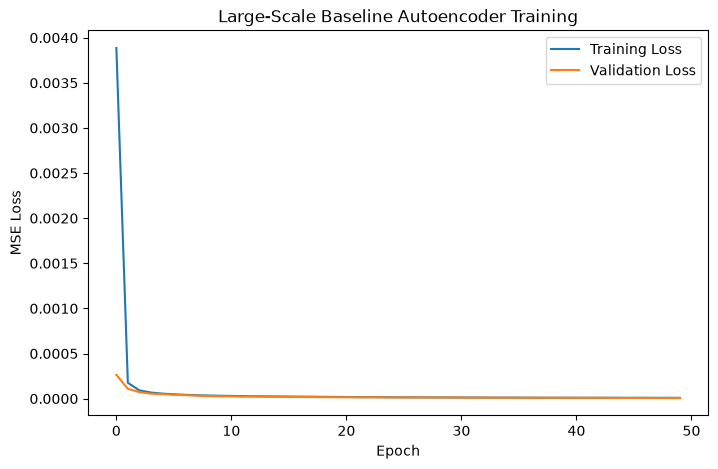

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Large-Scale Baseline Autoencoder Training")

plt.legend()
plt.show()

## Reconstruction Error

In [24]:
def reconstruction_error(model, X):

    reconstructed = model.predict(
        X,
        batch_size=2048,
        verbose=0
    )

    return np.mean(
        np.square(X - reconstructed),
        axis=1
    )

In [25]:
baseline_calibration_scores = reconstruction_error(
    large_baseline_ae,
    X_calibration_scaled
)

## Baseline Threshold

A 0.5% target benign false-positive rate is used for the baseline threshold.

In [26]:
BASELINE_TARGET_FPR = 0.005

baseline_threshold = np.quantile(
    baseline_calibration_scores,
    1 - BASELINE_TARGET_FPR
)

print(
    "Baseline threshold:",
    baseline_threshold
)

Baseline threshold: 0.00017626635874024482


In [27]:
def evaluate_predictions(
    name,
    y_true,
    y_pred
):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "FPR": fp / (fp + tn),
        "FNR": fn / (fn + tp)
    }

## Baseline Development Results

In [28]:
baseline_hpo_results = []

for test_name, X_hpo, y_hpo in [
    ("0.2%", X_hpo_02_scaled, y_hpo_02),
    ("1%", X_hpo_1_scaled, y_hpo_1),
    ("5%", X_hpo_5_scaled, y_hpo_5)
]:

    scores = reconstruction_error(
        large_baseline_ae,
        X_hpo
    )

    predictions = (
        scores > baseline_threshold
    ).astype(int)

    result = evaluate_predictions(
        "Large Baseline Autoencoder",
        y_hpo,
        predictions
    )

    baseline_hpo_results.append({
        "HPO Set": test_name,
        **result
    })

baseline_hpo_results_df = pd.DataFrame(
    baseline_hpo_results
)

baseline_hpo_results_df.round(4)

,HPO Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Large Baseline Autoencoder,0.9944,0.1786,0.500,0.2632,0.0046,0.500
1,1%,Large Baseline Autoencoder,0.9903,0.5158,0.490,0.5026,0.0046,0.510
2,5%,Large Baseline Autoencoder,0.9719,0.8567,0.526,0.6518,0.0046,0.474


In [29]:
print(
    "Mean Baseline HPO F1:",
    round(
        baseline_hpo_results_df[
            "F1-Score"
        ].mean(),
        4
    )
)

Mean Baseline HPO F1: 0.4725


### Observation

The large-scale baseline Autoencoder achieves a mean development F1-score of 0.4725.

At the 5% anomaly rate, it achieves an F1-score of 0.6518 with high Precision of 0.8567 while maintaining a low false-positive rate of approximately 0.46%. This provides a strong baseline before hyperparameter optimization.

# Experiment 2 - Large-Scale Autoencoder with Optuna

Optuna is used to optimize the Autoencoder architecture, training parameters and anomaly threshold.

All candidate Autoencoders are trained exclusively on benign traffic. HPO development labels are used only to compare candidate configurations, while final holdout sets remain untouched.

In [30]:
def build_autoencoder(
    input_dim,
    encoding_dim,
    hidden_dim,
    n_hidden_layers,
    dropout,
    l2_value,
    learning_rate
):

    inputs = keras.Input(
        shape=(input_dim,)
    )

    x = inputs

    for _ in range(n_hidden_layers):

        x = layers.Dense(
            hidden_dim,
            activation="relu",
            kernel_regularizer=regularizers.l2(
                l2_value
            )
        )(x)

        x = layers.Dropout(
            dropout
        )(x)

    encoded = layers.Dense(
        encoding_dim,
        activation="relu"
    )(x)

    x = encoded

    for _ in range(n_hidden_layers):

        x = layers.Dense(
            hidden_dim,
            activation="relu",
            kernel_regularizer=regularizers.l2(
                l2_value
            )
        )(x)

        x = layers.Dropout(
            dropout
        )(x)

    outputs = layers.Dense(
        input_dim,
        activation="linear"
    )(x)

    model = keras.Model(
        inputs,
        outputs
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse"
    )

    return model

## Optuna Objective

The objective maximizes mean F1-score across the 0.2%, 1% and 5% development sets so that optimization is not dominated by one anomaly prevalence.

In [31]:
optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

def objective_large_ae(trial):

    tf.keras.backend.clear_session()

    encoding_dim = trial.suggest_categorical(
        "encoding_dim",
        [8, 16, 32, 48]
    )

    hidden_dim = trial.suggest_categorical(
        "hidden_dim",
        [64, 128, 192, 256]
    )

    n_hidden_layers = trial.suggest_int(
        "n_hidden_layers",
        1,
        3
    )

    learning_rate = trial.suggest_float(
        "learning_rate",
        1e-5,
        1e-3,
        log=True
    )

    dropout = trial.suggest_float(
        "dropout",
        0.0,
        0.25
    )

    l2_value = trial.suggest_float(
        "l2",
        1e-7,
        1e-3,
        log=True
    )

    batch_size = trial.suggest_categorical(
        "batch_size",
        [512, 1024, 2048]
    )

    target_fpr = trial.suggest_float(
        "target_fpr",
        0.001,
        0.03,
        log=True
    )

    model = build_autoencoder(
        input_dim=X_train_scaled.shape[1],
        encoding_dim=encoding_dim,
        hidden_dim=hidden_dim,
        n_hidden_layers=n_hidden_layers,
        dropout=dropout,
        l2_value=l2_value,
        learning_rate=learning_rate
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    model.fit(
        X_train_scaled,
        X_train_scaled,
        epochs=30,
        batch_size=batch_size,
        validation_split=0.1,
        callbacks=[early_stopping],
        verbose=0
    )

    calibration_scores = reconstruction_error(
        model,
        X_calibration_scaled
    )

    threshold = np.quantile(
        calibration_scores,
        1 - target_fpr
    )

    f1_scores = []

    for X_dev, y_dev in [
        (X_hpo_02_scaled, y_hpo_02),
        (X_hpo_1_scaled, y_hpo_1),
        (X_hpo_5_scaled, y_hpo_5)
    ]:

        scores = reconstruction_error(
            model,
            X_dev
        )

        predictions = (
            scores > threshold
        ).astype(int)

        f1_scores.append(
            f1_score(
                y_dev,
                predictions,
                zero_division=0
            )
        )

    return np.mean(f1_scores)

## Run Optuna Optimization

In [32]:
large_ae_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

large_ae_study.optimize(
    objective_large_ae,
    n_trials=20,
    show_progress_bar=True
)

print(
    "Best mean HPO F1:",
    round(
        large_ae_study.best_value,
        4
    )
)

print("\nBest parameters:")

for parameter, value in (
    large_ae_study.best_params.items()
):
    print(
        parameter,
        ":",
        value
    )

  0%|          | 0/20 [00:00<?, ?it/s]

Best trial: 11. Best value: 0.584135: 100%|██████████| 20/20 [41:37<00:00, 124.89s/it]  

Best mean HPO F1: 0.5841

Best parameters:
encoding_dim : 8
hidden_dim : 192
n_hidden_layers : 2
learning_rate : 0.0005966464941062595
dropout : 0.0817760418076908
l2 : 1.3405491159668705e-07
batch_size : 2048
target_fpr : 0.01237896223546739


### Observation

Optuna improves the large-scale Autoencoder mean development F1-score from 0.4725 to 0.5841.

The best configuration uses an 8-dimensional latent space, two hidden layers of 192 units, a learning rate of approximately 5.97×10⁻⁴ and a calibrated target false-positive rate of about 1.24%.

## Rebuild Best Large-Scale Autoencoder

In [33]:
best_large_params = large_ae_study.best_params.copy()

best_large_target_fpr = best_large_params.pop(
    "target_fpr"
)

best_large_batch_size = best_large_params.pop(
    "batch_size"
)

best_large_ae = build_autoencoder(
    input_dim=X_train_scaled.shape[1],
    encoding_dim=best_large_params["encoding_dim"],
    hidden_dim=best_large_params["hidden_dim"],
    n_hidden_layers=best_large_params["n_hidden_layers"],
    dropout=best_large_params["dropout"],
    l2_value=best_large_params["l2"],
    learning_rate=best_large_params["learning_rate"]
)

In [34]:
best_large_es = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

best_large_history = best_large_ae.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=50,
    batch_size=best_large_batch_size,
    validation_split=0.1,
    callbacks=[best_large_es],
    verbose=1
)

Epoch 1/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 12s 44ms/step - loss: 0.0101 - val_loss: 0.0023
Epoch 2/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 0.0026 - val_loss: 9.9855e-04
Epoch 3/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 0.0017 - val_loss: 6.6299e-04
Epoch 4/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0013 - val_loss: 4.7903e-04
Epoch 5/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0010 - val_loss: 3.6631e-04
Epoch 6/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 8.7485e-04 - val_loss: 3.1247e-04
Epoch 7/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 7.7803e-04 - val_loss: 2.7678e-04
Epoch 8/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - loss: 7.1290e-04 - val_loss: 2.4241e-04
Epoch 9/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 6.6314e-04 - val_loss: 2.2946e-04
Epoch 10/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - loss: 6.2474e-04 - val_loss: 2.2869e-04
Epoch 11/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 5.9263e-04

## Calibrate Final Threshold

In [35]:
best_large_calibration_scores = reconstruction_error(
    best_large_ae,
    X_calibration_scaled
)

best_large_threshold = np.quantile(
    best_large_calibration_scores,
    1 - best_large_target_fpr
)

print(
    "Chosen target FPR:",
    round(best_large_target_fpr, 5)
)

print(
    "Threshold:",
    best_large_threshold
)

Chosen target FPR: 0.01238
Threshold: 0.0006699915003013917


## Development Evaluation of Best Tuned Model

In [36]:
best_large_dev_results = []

for test_name, X_dev, y_dev in [
    ("0.2%", X_hpo_02_scaled, y_hpo_02),
    ("1%", X_hpo_1_scaled, y_hpo_1),
    ("5%", X_hpo_5_scaled, y_hpo_5)
]:

    scores = reconstruction_error(
        best_large_ae,
        X_dev
    )

    predictions = (
        scores > best_large_threshold
    ).astype(int)

    result = evaluate_predictions(
        "Large Tuned Autoencoder",
        y_dev,
        predictions
    )

    best_large_dev_results.append({
        "HPO Set": test_name,
        **result
    })

best_large_dev_results_df = pd.DataFrame(
    best_large_dev_results
)

best_large_dev_results_df.round(4)

,HPO Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Large Tuned Autoencoder,0.9881,0.1439,1.000,0.2516,0.0119,0.000
1,1%,Large Tuned Autoencoder,0.9882,0.4587,1.000,0.6289,0.0119,0.000
2,5%,Large Tuned Autoencoder,0.9888,0.8180,0.998,0.8991,0.0117,0.002


In [37]:
print(
    "Mean Tuned Development F1:",
    round(
        best_large_dev_results_df[
            "F1-Score"
        ].mean(),
        4
    )
)

Mean Tuned Development F1: 0.5932


### Observation

The rebuilt tuned Autoencoder confirms the Optuna improvement, achieving a mean development F1-score of 0.5932.

At the 5% anomaly rate, it reaches an F1-score of 0.8991 with Recall of 0.9980 and Precision of 0.8180, while maintaining a false-positive rate of approximately 1.17%.

# Final Holdout Evaluation

The tuned Autoencoder is evaluated once on the previously unseen final holdout datasets.

No further model, threshold, or preprocessing changes are made after this point.

In [38]:
final_large_results = []

for test_name, X_final, y_final in [
    ("0.2%", X_final_02_scaled, y_final_02),
    ("1%", X_final_1_scaled, y_final_1),
    ("5%", X_final_5_scaled, y_final_5)
]:

    scores = reconstruction_error(
        best_large_ae,
        X_final
    )

    predictions = (
        scores > best_large_threshold
    ).astype(int)

    result = evaluate_predictions(
        "Large Tuned Autoencoder",
        y_final,
        predictions
    )

    final_large_results.append({
        "Test Set": test_name,
        **result
    })

final_large_results_df = pd.DataFrame(
    final_large_results
)

final_large_results_df.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Large Tuned Autoencoder,0.9883,0.1460,1.000,0.2548,0.0117,0.000
1,1%,Large Tuned Autoencoder,0.9884,0.4622,1.000,0.6322,0.0118,0.000
2,5%,Large Tuned Autoencoder,0.9887,0.8171,0.998,0.8986,0.0118,0.002


In [39]:
print(
    "Mean Final F1:",
    round(
        final_large_results_df[
            "F1-Score"
        ].mean(),
        4
    )
)

Mean Final F1: 0.5952


## Final 5% Confusion Matrix

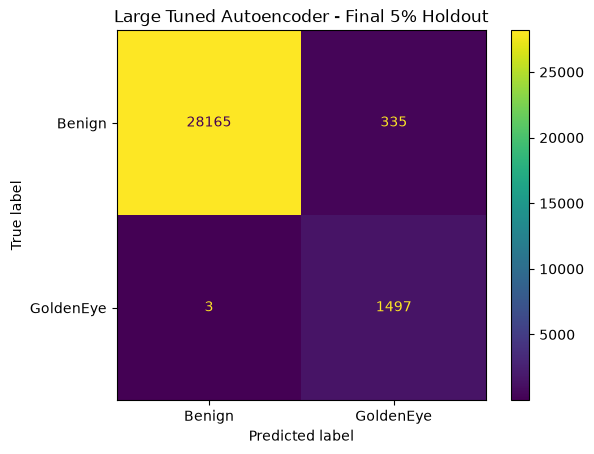

In [40]:
final_5_scores = reconstruction_error(
    best_large_ae,
    X_final_5_scaled
)

final_5_pred = (
    final_5_scores
    > best_large_threshold
).astype(int)

cm = confusion_matrix(
    y_final_5,
    final_5_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Benign",
        "GoldenEye"
    ]
)

disp.plot()

plt.title(
    "Large Tuned Autoencoder - Final 5% Holdout"
)

plt.show()

## Final 5% Classification Report

In [41]:
print(
    classification_report(
        y_final_5,
        final_5_pred,
        target_names=[
            "Benign",
            "GoldenEye"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

      Benign     0.9999    0.9882    0.9940     28500
   GoldenEye     0.8171    0.9980    0.8986      1500

    accuracy                         0.9887     30000
   macro avg     0.9085    0.9931    0.9463     30000
weighted avg     0.9908    0.9887    0.9893     30000



### Observation

The tuned large-scale Autoencoder generalizes well to the unseen final holdout sets.

At the 5% anomaly rate, the model achieves an F1-score of 0.8986 with Precision of 0.8171 and Recall of 0.9980. The false-positive rate remains approximately 1.18%, while the false-negative rate is only 0.20%.

The close agreement between development and final holdout performance indicates that the optimized model generalizes consistently rather than overfitting to the development data.

# Final Summary

In [42]:
large_summary = pd.DataFrame([
    {
        "Configuration": "Baseline Autoencoder",
        "Mean Development F1": baseline_hpo_results_df[
            "F1-Score"
        ].mean(),
        "5% Development F1": baseline_hpo_results_df.loc[
            baseline_hpo_results_df["HPO Set"] == "5%",
            "F1-Score"
        ].values[0]
    },
    {
        "Configuration": "Optuna-Tuned Autoencoder",
        "Mean Development F1": best_large_dev_results_df[
            "F1-Score"
        ].mean(),
        "5% Development F1": best_large_dev_results_df.loc[
            best_large_dev_results_df["HPO Set"] == "5%",
            "F1-Score"
        ].values[0]
    }
])

large_summary.round(4)

,Configuration,Mean Development F1,5% Development F1
0,Baseline Autoencoder,0.4725,0.6518
1,Optuna-Tuned Autoencoder,0.5932,0.8991


## Save Results

In [43]:
RESULTS_PATH = Path("../results")
RESULTS_PATH.mkdir(
    parents=True,
    exist_ok=True
)

baseline_hpo_results_df.to_csv(
    RESULTS_PATH / "large_benign_baseline_results.csv",
    index=False
)

best_large_dev_results_df.to_csv(
    RESULTS_PATH / "large_benign_tuned_development_results.csv",
    index=False
)

final_large_results_df.to_csv(
    RESULTS_PATH / "large_benign_final_results.csv",
    index=False
)

large_summary.to_csv(
    RESULTS_PATH / "large_benign_summary.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


## Best Hyperparameters

In [44]:
best_large_parameters = pd.DataFrame([
    large_ae_study.best_params
])

best_large_parameters

,encoding_dim,hidden_dim,n_hidden_layers,learning_rate,dropout,l2,batch_size,target_fpr
0,8,192,2,0.000597,0.081776,1.340549e-07,2048,0.012379


In [45]:
best_large_parameters.to_csv(
    RESULTS_PATH / "large_benign_best_parameters.csv",
    index=False
)

# Conclusion

The large-scale benign-only experiment evaluated an Autoencoder trained on 300,000 benign network flows from the CSE-CIC-IDS2018 dataset.

The baseline Autoencoder achieved a mean development F1-score of 0.4725. Hyperparameter optimization using Optuna improved the mean development F1-score to 0.5932.

The optimized Autoencoder generalized strongly to previously unseen holdout data. At the 5% anomaly rate, it achieved an F1-score of 0.8986, Precision of 0.8171 and Recall of 0.9980, with a false-positive rate of approximately 1.18%.

These results indicate that increasing the amount of benign training data and tuning the Autoencoder architecture substantially improves GoldenEye anomaly detection while maintaining a low false-negative rate.